# Bayesian Analysis of Semantic Alignment in Large Language Models

## 1. Introduction & Research Objective

### 1.1 Background

This prototype extends our previous exploratory analysis of human and LLM-generated word associations.

In the original EDA, we compared associations from **SWOW (human participants)** with those generated by **Llama3** and **Mistral**, using 11,298 aligned cue words.

Our analysis revealed differences in response diversity, concentration, and exact lexical overlap with human associations.

However, the previous overlap metric considered only **distinct responses**, without accounting for how frequently each association was generated.

### 1.2 Research Objective

The objective of this prototype is to investigate whether Mistral and Llama3 differ in their underlying probability of generating associations observed in SWOW.

Rather than relying exclusively on observed averages, we use **Bayesian inference** to estimate these probabilities and quantify uncertainty.

We focus on two research questions:

- **RQ1:** Does Mistral generate human-observed associations more frequently than Llama3?
- **RQ2 (Exploratory):** Does the difference in alignment vary across cue words?

### 1.3 Prototype Scope

The prototype focuses on:

1. Computing response-level alignment from the existing datasets.
2. Defining a simple Bayesian probabilistic model.
3. Estimating posterior distributions for alignment probabilities.
4. Comparing the two LLMs using posterior differences.
5. Evaluating the model through basic diagnostics and posterior predictive checks.
6. Exploring cue-word variability as preparation for the full project.

The hierarchical modeling extension and the relationship between response concentration and alignment are reserved for the full study.

**Note:** Alignment refers to exact agreement with human-observed associations in SWOW, not a direct measure of semantic understanding.

## 2. Dataset Description

This prototype reuses the datasets prepared in our previous EDA, consisting of human and LLM-generated word associations.

### 2.1 Data Sources

- **SWOW (Small World of Words):** Human-generated word associations, used as the reference for observed human responses.
- **LWOW Llama3:** Word associations generated by Llama3.
- **LWOW Mistral:** Word associations generated by Mistral.

All three datasets contain cue words and up to three associated responses per observation (`R1`, `R2`, `R3`).

Our previous EDA identified **11,298 common cue words**, allowing us to compare both LLMs against the same human reference.

### 2.2 Previous EDA Findings

Our exploratory analysis investigated response diversity, concentration, and exact lexical overlap with SWOW.

The mean distinct-response overlap was:

- **Llama3:** 21.26%
- **Mistral:** 42.48%

These values describe the proportion of distinct LLM responses also observed in SWOW. They do not account for how frequently individual responses were generated.

### 2.3 Response-Level Alignment

For this prototype, we introduce a frequency-aware alignment measure.

A generated response is considered a **match** if it appears among the observed SWOW responses for the same cue word.

For each LLM and cue word, we will calculate:

- **Matches:** Number of generated responses matching SWOW.
- **Total responses:** Number of valid generated responses.
- **Observed alignment rate:** Matches divided by total responses.

Unlike distinct-response overlap, this measure counts repeated responses, allowing frequently generated associations to contribute proportionally.

The resulting observations will be used to estimate the underlying alignment probabilities through Bayesian inference.

**Limitation:** Exact lexical agreement with SWOW does not necessarily represent semantic correctness or similarity. Responses absent from SWOW may still be semantically meaningful.

## 3. Data Loading & Preparation

This prototype reuses the cleaned and transformed datasets from our previous EDA.

The preprocessing steps, including normalization and conversion into individual cue-response associations, were performed in `EDA_llm_cognition.ipynb`.

The resulting datasets were exported to `data/processed/`, preserving the original response frequencies.

### 3.1 Loading Preprocessed Data

We load the preprocessed SWOW, Llama3, and Mistral associations and inspect their structure before constructing the observations for Bayesian inference.

In [4]:
import pandas as pd
from pathlib import Path

processed_dir = Path("data/processed")

swow_long = pd.read_csv(processed_dir / "swow_long.csv")
llama_long = pd.read_csv(processed_dir / "llama3_long.csv")
mistral_long = pd.read_csv(processed_dir / "mistral_long.csv")

datasets = {
    "SWOW": swow_long,
    "Llama3": llama_long,
    "Mistral": mistral_long
}

for name, df in datasets.items():
    print(f"\n{name}: {len(df):,} associations")
    display(df.head(3))
    print(df.columns.tolist())



SWOW: 3,403,790 associations


,cue,position,response
0,although,R1,nevertheless
1,deal,R1,no
2,music,R1,notes


['cue', 'position', 'response']

Llama3: 3,348,049 associations


,cue,position,response
0,a,R1,absorbent
1,a,R1,absorbent
2,a,R1,absorbent


['cue', 'position', 'response']

Mistral: 3,268,206 associations


,cue,position,response
0,a,R1,airplane
1,a,R1,also
2,a,R1,an


['cue', 'position', 'response']


### 3.2 Cue Alignment & Validation

To ensure a fair comparison, we restrict the analysis to cue words with valid responses in all three datasets.

We reuse the alignment criterion established in the previous EDA, preserving only cues shared by SWOW, Llama3, and Mistral.

This ensures both LLMs are compared against the same human reference words.

In [5]:
aligned_cues = (
    set(swow_long["cue"])
    & set(llama_long["cue"])
    & set(mistral_long["cue"])
)

print(f"Aligned cue words: {len(aligned_cues):,}")

assert len(aligned_cues) == 11298, "Cue alignment differs from the original EDA."


Aligned cue words: 11,298


### 3.3 Filtering Aligned Associations

We restrict each dataset to the 11,298 common cue words identified in the previous step.

This ensures that all subsequent measurements are calculated over the same set of stimuli, while preserving individual responses and their frequencies.

In [6]:
swow_aligned = swow_long[swow_long["cue"].isin(aligned_cues)].copy()
llama_aligned = llama_long[llama_long["cue"].isin(aligned_cues)].copy()
mistral_aligned = mistral_long[mistral_long["cue"].isin(aligned_cues)].copy()

for name, df in {
    "SWOW": swow_aligned,
    "Llama3": llama_aligned,
    "Mistral": mistral_aligned
}.items():
    print(f"{name}: {len(df):,} associations, {df['cue'].nunique():,} cues")

    assert df["cue"].nunique() == len(aligned_cues)


SWOW: 3,127,866 associations, 11,298 cues
Llama3: 3,329,829 associations, 11,298 cues
Mistral: 3,241,259 associations, 11,298 cues


### 3.4 Response-Level Matching

We identify whether each LLM-generated response appears among the human-observed associations in SWOW for the same cue word.

Unlike the distinct-response overlap measure used in the previous EDA, repeated responses are counted individually.

Each LLM response is classified as:

- **Match (1):** The response appears in SWOW for the same cue.
- **Non-match (0):** The response does not appear in SWOW for that cue.

These binary observations will subsequently be aggregated into success counts and total response counts for Bayesian modeling.

In [7]:
swow_pairs = swow_aligned[["cue", "response"]].drop_duplicates()

llama_matches = llama_aligned.merge(
    swow_pairs.assign(match=1),
    on=["cue", "response"],
    how="left"
)

mistral_matches = mistral_aligned.merge(
    swow_pairs.assign(match=1),
    on=["cue", "response"],
    how="left"
)

llama_matches["match"] = llama_matches["match"].fillna(0).astype(int)
mistral_matches["match"] = mistral_matches["match"].fillna(0).astype(int)

display(llama_matches.head())
display(mistral_matches.head())


,cue,position,response,match
0,a,R1,absorbent,0
1,a,R1,absorbent,0
2,a,R1,absorbent,0
3,a,R1,abundance,0
4,a,R1,acorn,0


,cue,position,response,match
0,a,R1,airplane,0
1,a,R1,also,0
2,a,R1,an,1
3,a,R1,an,1
4,a,R1,an,1


In [8]:
for name, original, matched in [
    ("Llama3", llama_aligned, llama_matches),
    ("Mistral", mistral_aligned, mistral_matches)
]:
    assert len(original) == len(matched)
    assert matched["match"].isin([0, 1]).all()

    print(f"{name}:")
    print(f"  Total responses: {len(matched):,}")
    print(f"  Matched responses: {matched['match'].sum():,}")
    print(f"  Observed match rate: {matched['match'].mean():.2%}")


Llama3:
  Total responses: 3,329,829
  Matched responses: 827,351
  Observed match rate: 24.85%
Mistral:
  Total responses: 3,241,259
  Matched responses: 2,377,671
  Observed match rate: 73.36%


### 3.5 Aggregating Observations per Cue Word

We aggregate the binary response matches for each cue word and LLM.

For every cue-model pair, we calculate the number of matching responses, the total number of valid responses, and the observed alignment rate.

We preserve cue-level observations to support future analysis of variation across words, rather than relying exclusively on overall aggregated rates.

In [9]:
llama_counts = llama_matches.groupby("cue")["match"].agg(
    matches="sum",
    total="count"
).reset_index()

mistral_counts = mistral_matches.groupby("cue")["match"].agg(
    matches="sum",
    total="count"
).reset_index()

llama_counts["model"] = "Llama3"
mistral_counts["model"] = "Mistral"

alignment_data = pd.concat(
    [llama_counts, mistral_counts],
    ignore_index=True
)

alignment_data["alignment_rate"] = (
    alignment_data["matches"] / alignment_data["total"]
)

display(alignment_data.head())
print(f"Observations: {len(alignment_data):,}")


,cue,matches,total,model,alignment_rate
0,a,21,300,Llama3,0.070000
1,a few,91,300,Llama3,0.303333
2,a little,74,300,Llama3,0.246667
3,a lot,60,300,Llama3,0.200000
4,aardvark,33,300,Llama3,0.110000


Observations: 22,596


## 4. Preliminary Data Analysis

Before specifying the Bayesian model, we examine the distribution of observed response-level alignment rates across cue words.

Our previous analysis showed a substantial difference in overall alignment between Llama3 and Mistral. However, these aggregate rates do not reveal how consistently the difference appears across individual cues.

This preliminary analysis examines cue-level variation and establishes a descriptive baseline for subsequent posterior inference.

### 4.1 Alignment Distribution by Model

We compare the mean, median, and standard deviation of cue-level alignment rates for each LLM.

Unlike the overall response-weighted alignment rate, these summaries give each cue word equal weight.

In [10]:
alignment_summary = alignment_data.groupby("model")["alignment_rate"].agg(
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
)

display(alignment_summary.round(4))


,mean,median,std,min,max
model,,,,,
Llama3,0.2500,0.2267,0.1372,0.0,0.9614
Mistral,0.7297,0.7633,0.1755,0.0,1.0000


### 4.2 Paired Alignment Differences

Since both LLMs are evaluated on the same aligned cue words, we compare their observed alignment rates directly.

For each cue word, we calculate the difference between Mistral and Llama3.

A positive difference indicates higher observed alignment for Mistral, while a negative difference indicates higher observed alignment for Llama3.

This descriptive comparison helps assess whether the overall difference is widespread across cue words or concentrated in particular cases. It also provides a reference for subsequent Bayesian posterior comparisons.

In [11]:
paired_alignment = alignment_data.pivot(
    index="cue",
    columns="model",
    values="alignment_rate"
)

paired_alignment["difference"] = (
    paired_alignment["Mistral"] - paired_alignment["Llama3"]
)

display(paired_alignment.head())

print(f"Mean difference: {paired_alignment['difference'].mean():.4f}")
print(f"Median difference: {paired_alignment['difference'].median():.4f}")
print(f"Mistral higher: {(paired_alignment['difference'] > 0).mean():.2%}")
print(f"Llama3 higher: {(paired_alignment['difference'] < 0).mean():.2%}")
print(f"Equal: {(paired_alignment['difference'] == 0).mean():.2%}")


model,Llama3,Mistral,difference
cue,,,
a,0.070000,0.409483,0.339483
a few,0.303333,0.539267,0.235934
a little,0.246667,0.512281,0.265614
a lot,0.200000,0.588235,0.388235
aardvark,0.110000,0.507634,0.397634


Mean difference: 0.4798
Median difference: 0.5132
Mistral higher: 97.39%
Llama3 higher: 2.59%
Equal: 0.02%


In [12]:

import plotly.express as px

fig = px.histogram(
    paired_alignment,
    x="difference",
    nbins=40,
    title="Cue-Level Alignment Differences",
    labels={
        "difference": "Observed alignment difference (Mistral - Llama3)"
    }
)

fig.add_vline(x=0, line_dash="dash", line_color="black")

fig.update_layout(
    xaxis_title="Observed alignment difference (Mistral - Llama3)",
    yaxis_title="Number of cue words",
    showlegend=False
)

fig.show()


### 4.3 Data Preparation & Preliminary Findings

The preprocessing and preliminary analysis established the following:

**1. Data preparation and validation**

- Reused the cleaned SWOW, Llama3, and Mistral datasets from the previous EDA, without repeating normalization.
- Confirmed **11,298 aligned cue words** across all three datasets.
- Constructed response-level matching indicators while preserving repeated associations.
- Aggregated the observations into **22,596 cue-model records**, containing matching response counts, total response counts, and observed alignment rates.
- Successfully validated the resulting data.

**2. Response-level alignment**

The mean cue-level alignment rates were:

- **Llama3:** 25.00%
- **Mistral:** 72.97%

Unlike the distinct-response overlap calculated in the previous EDA, these measurements account for response frequencies.

**3. Cue-level differences**

- The mean observed alignment difference (Mistral / Llama3) was **0.4798**, or approximately **47.98 percentage points**.
- Mistral exhibited higher observed alignment for **97.39%** of cue words.
- Llama3 exhibited higher observed alignment for **2.59%** of cue words.
- The remaining **0.02%** showed equal alignment.

The distribution of paired differences was predominantly positive, indicating that Mistral's advantage is widespread across cue words rather than being driven exclusively by a small subset.

**4. Interpretation and next steps**

These findings provide strong descriptive evidence of higher exact lexical agreement with SWOW for Mistral. However, they do not establish superior semantic understanding or explain the underlying causes of the difference.

Furthermore, the observed rates and differences are point estimates that do not directly quantify uncertainty about the underlying alignment probabilities.

The next stage introduces Bayesian probabilistic modeling to estimate:

- **Posterior A:** The underlying response-level alignment probability for each LLM.
- **Posterior B:** The difference between the two alignment probabilities and its uncertainty.

The variability across cue words will be investigated further in the full study through hierarchical Bayesian modeling.

## 5. Bayesian Model Specification

### 5.1 Generative Story

We assume that each LLM has an unknown underlying probability of generating a response that matches a human-observed association in SWOW.

For each generated response, two outcomes are possible:

- **Success (1):** The response appears in SWOW for the same cue word.
- **Failure (0):** The response does not appear in SWOW for the same cue word.

The generative process can be described as follows:

1. Each LLM has an unknown alignment probability.
2. Individual responses are classified as matches or non-matches according to this probability.
3. The number of matching responses is observed.
4. Bayesian inference uses these observations to estimate the unknown alignment probabilities.

The model contains the following variables:

- **Observed variables:** Number of matching responses for each LLM.
- **Known quantities:** Total number of valid responses for each LLM.
- **Latent variables:** Unknown alignment probabilities for Llama3 and Mistral.
- **Deterministic variable:** Difference between the two alignment probabilities.
- **Predicted variables:** Replicated match counts used for posterior predictive evaluation.

| Variable | Type | Description |
|---|---|---|
| $n_L, n_M$ | Known constants | Total number of valid responses |
| $Y_L, Y_M$ | Observed RVs | Number of observed matches |
| $p_L, p_M$ | Latent RVs | Unknown alignment probabilities |
| $\Delta = p_M - p_L$ | Deterministic variable | Difference between alignment probabilities |
| $Y_L^{rep}, Y_M^{rep}$ | Predicted RVs | Replicated match counts for PPC |

The baseline model assumes a common alignment probability for all responses generated by each LLM, with responses conditionally independent given that probability.

This simplifying assumption allows us to construct an initial probabilistic comparison. However, it does not explicitly account for cue-level variability or dependence between responses.

These limitations motivate the hierarchical extension proposed for the full project.


### 5.2 Prior and Likelihood Specification

#### Prior Distribution

We assign independent Beta distributions to the unknown alignment
probabilities of both LLMs:

$$
p_L \sim \operatorname{Beta}(1,1)
$$

$$
p_M \sim \operatorname{Beta}(1,1)
$$

The Beta distribution is suitable for modeling unknown probabilities,
as its support is bounded between 0 and 1.

With both shape parameters equal to 1, the Beta distribution is
equivalent to a Uniform distribution:

$$
\operatorname{Beta}(1,1) = \operatorname{Uniform}(0,1)
$$

Therefore, our prior assigns equal probability density across the
entire interval, without favoring higher or lower alignment probabilities.

Although we could directly use a Uniform distribution, we choose
the Beta formulation for two reasons:

- **Conjugacy:** The Beta distribution is the conjugate prior for
  the Binomial likelihood, meaning that the resulting posterior
  also belongs to the Beta distribution family.
- **Flexibility:** Different values of the shape parameters allow
  us to express different prior beliefs without changing the
  distribution family.

The posterior can also be derived analytically:

$$
p \mid Y=y \sim \operatorname{Beta}(\alpha+y,\beta+n-y)
$$

This provides an analytical reference against which we can verify
the posterior estimates obtained through MCMC sampling.

We use identical priors for both models to avoid favoring
either LLM before conditioning on the observed data.

Although the preliminary analysis revealed substantial differences,
these empirical results are not used to construct the priors,
avoiding the reuse of the same evidence.

#### Likelihood Distribution

Each generated response represents a binary outcome: a match or
a non-match with SWOW.

We model the total number of matching responses using a Binomial
distribution:

$$
Y_L \mid p_L \sim \operatorname{Binomial}(n_L,p_L)
$$

$$
Y_M \mid p_M \sim \operatorname{Binomial}(n_M,p_M)
$$

| Model | Total responses ($n$) | Observed matches ($y$) |
|---|---:|---:|
| Llama3 | 3,329,829 | 827,351 |
| Mistral | 3,241,259 | 2,377,671 |

#### Deterministic Variable

To compare the two LLMs, we define:

$$
\Delta = p_M - p_L
$$

This deterministic variable allows us to derive the posterior
distribution of the alignment difference directly from the
posterior samples of both probabilities.


#### Posterior Distributions

By combining the prior distributions with the observed-data
likelihoods through Bayesian inference, we obtain two main
posterior quantities.

Let $D$ denote the observed response counts and match counts
for both LLMs.

##### Posterior A : Alignment Probabilities

We estimate the posterior distributions of the underlying
alignment probabilities:

$$
P(p_L \mid D)
$$

$$
P(p_M \mid D)
$$

Given the conjugacy between the Beta prior and the Binomial
likelihood, these posterior distributions can also be expressed
analytically:

$$
p_L \mid D \sim \operatorname{Beta}(1+y_L,1+n_L-y_L)
$$

$$
p_M \mid D \sim \operatorname{Beta}(1+y_M,1+n_M-y_M)
$$

These distributions allow us to estimate:

- The underlying alignment probability of each LLM.
- The uncertainty associated with each probability.
- Credible intervals for both alignment probabilities.

##### Posterior B : Difference Between LLMs

Using the deterministic variable:

$$
\Delta = p_M-p_L
$$

we obtain the posterior distribution:

$$
P(\Delta \mid D)
$$

This distribution allows us to investigate:

- The estimated magnitude of the alignment difference.
- The uncertainty associated with this difference.
- The posterior probability that Mistral has higher alignment
  than Llama3:

$$
P(\Delta > 0 \mid D)
$$

Rather than simply comparing observed alignment rates,
we estimate a distribution of plausible differences
conditioned on the available data and model assumptions.

Both posterior quantities will be estimated through MCMC sampling.
The analytical Beta posteriors will serve as reference distributions
for validating the numerical inference.


#### Model Assumptions

- Responses are conditionally independent given their model's
  alignment probability.
- Each LLM has a common alignment probability across cue words.
- SWOW is treated as a fixed reference of human-observed associations.

These assumptions simplify the initial model but do not explicitly
account for cue-level heterogeneity or dependencies between
responses. These limitations motivate future hierarchical modeling.


### 5.2.1 Graphical Summary of Bayesian Inference

$$
\begin{array}{ccc}
\textbf{Llama3} & & \textbf{Mistral} \\[8pt]

p_L \sim \operatorname{Beta}(1,1) & &
p_M \sim \operatorname{Beta}(1,1) \\[6pt]

+ & & + \\[6pt]

Y_L \sim \operatorname{Binomial}(n_L,p_L) & &
Y_M \sim \operatorname{Binomial}(n_M,p_M) \\[6pt]

\downarrow & & \downarrow \\[6pt]

\text{Bayesian inference} & &
\text{Bayesian inference} \\[6pt]

\downarrow & & \downarrow \\[6pt]

P(p_L \mid Y_L,n_L) & &
P(p_M \mid Y_M,n_M) \\[6pt]

\text{Posterior A} & & \text{Posterior A} \\[6pt]

\searrow & & \swarrow \\[6pt]

& \Delta = p_M-p_L & \\[6pt]

& \downarrow & \\[6pt]

& P(\Delta \mid D) & \\[6pt]

& \text{Posterior B} & \\[6pt]

& \downarrow & \\[6pt]

& P(\Delta > 0 \mid D) &
\end{array}
$$

The prior distributions and observed-data likelihoods are combined
through Bayesian inference to obtain the posterior distributions
of both alignment probabilities (Posterior A).

The difference between posterior samples is then used to derive
the posterior distribution of the alignment difference (Posterior B).

This allows us to estimate both the magnitude of the difference
and the posterior probability that Mistral has higher alignment
than Llama3.

Here, $D$ denotes the observed data from both LLMs.

### 5.3 PyMC Model Implementation

We implement the proposed Bayesian model using PyMC.

The model consists of:

- Two independent Beta priors for the alignment probabilities.
- Two Binomial likelihoods for the observed match counts.
- A deterministic variable representing the difference between
  the two alignment probabilities.

The observed data are extracted directly from the previously
prepared cue-level observations.

In [13]:
import pymc as pm
import arviz as az
import numpy as np

In [14]:
# use again from 3.5, lazy to rerun :P
n_llama = llama_counts["total"].sum()
y_llama = llama_counts["matches"].sum()

n_mistral = mistral_counts["total"].sum()
y_mistral = mistral_counts["matches"].sum()

print(f"Llama3: {y_llama:,} / {n_llama:,}")
print(f"Mistral: {y_mistral:,} / {n_mistral:,}")

Llama3: 827,351 / 3,329,829
Mistral: 2,377,671 / 3,241,259


In [15]:
with pm.Model() as model:

    p_llama = pm.Beta("p_llama", alpha=1, beta=1)
    p_mistral = pm.Beta("p_mistral", alpha=1, beta=1)

    obs_llama = pm.Binomial(
        "obs_llama",
        n=n_llama,
        p=p_llama,
        observed=y_llama
    )

    obs_mistral = pm.Binomial(
        "obs_mistral",
        n=n_mistral,
        p=p_mistral,
        observed=y_mistral
    )

    # the det var
    delta = pm.Deterministic(
        "delta",
        p_mistral - p_llama
    )

In [16]:
print("Basic RVs:", model.basic_RVs)
print("Free RVs:", model.free_RVs)
print("Observed RVs:", model.observed_RVs)
print("Deterministic variables:", model.deterministics)

Basic RVs: [p_llama, p_mistral, obs_llama, obs_mistral]
Free RVs: [p_llama, p_mistral]
Observed RVs: [obs_llama, obs_mistral]
Deterministic variables: [delta]


## 6. Posterior Inference & Analysis

After specifying the probabilistic model, we perform Bayesian
inference to approximate the posterior distributions of the
unknown alignment probabilities and their difference.

### 6.1 MCMC Sampling

We use the No-U-Turn Sampler (NUTS), a variant of Hamiltonian
Monte Carlo (HMC), to explore the posterior distribution.

The resulting posterior samples will be used to estimate
alignment probabilities, compare the two LLMs, and quantify
uncertainty.

Since the Beta-Binomial model admits an analytical posterior,
we will also compare the numerical estimates against the
analytical solution.

In [17]:
with model:
    trace = pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [p_llama, p_mistral]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


### 6.2 Convergence Diagnostics

Before interpreting the posterior distributions, we evaluate
the quality of the MCMC sampling process.

We inspect the trace plots of the four Markov chains to assess:

- Convergence towards a common posterior distribution.
- Mixing between the chains.
- Potential trends or sampling irregularities.
- Differences between independently initialized chains.

Visual diagnostics are complemented by numerical convergence
metrics.

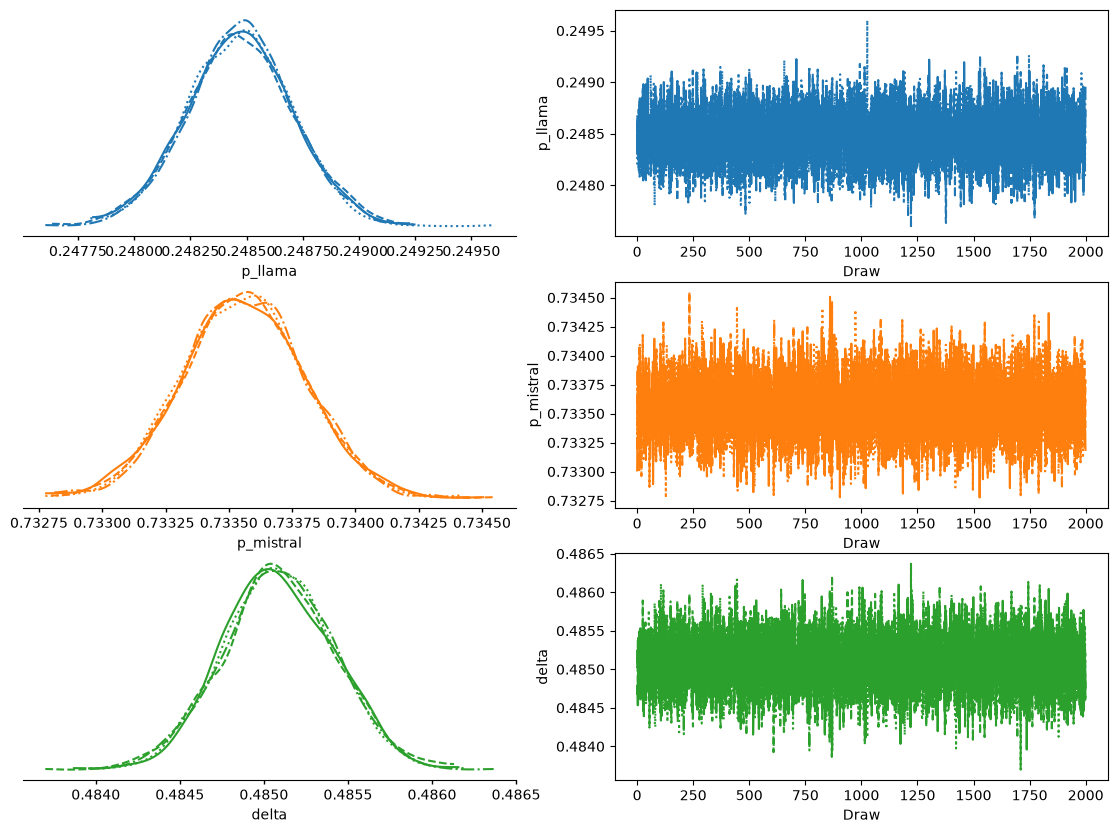

In [20]:
import arviz_plots as azp

pc = azp.plot_trace_dist(
    trace,
    var_names=["p_llama", "p_mistral", "delta"],
    backend="matplotlib",
    figure_kwargs={"figsize": (14, 10)}
)

pc.show()

In [21]:
import arviz_stats as azs

diagnostics = azs.summary(
    trace,
    var_names=["p_llama", "p_mistral", "delta"],
    kind="diagnostics",
    round_to=6
)

display(diagnostics)

,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
p_llama,7863.089756,5936.598980,1.001120,0.000003,0.000003
p_mistral,7897.256818,5728.724461,0.999905,0.000003,0.000003
delta,7737.234890,5785.191902,1.000363,0.000004,0.000004


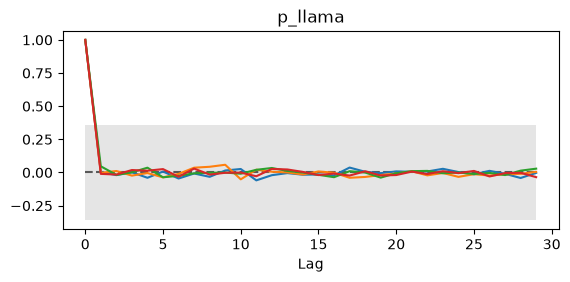

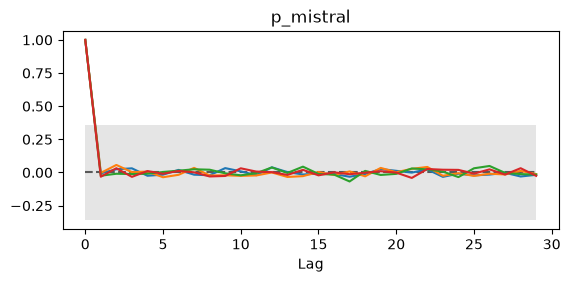

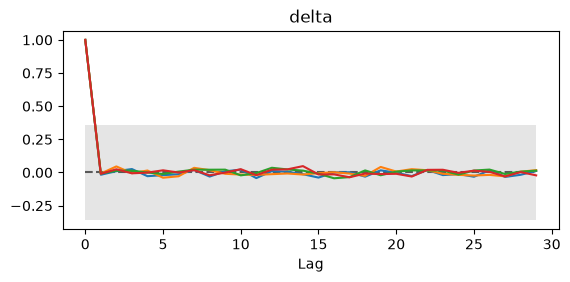

In [22]:
for variable in ["p_llama", "p_mistral", "delta"]:
    pc = azp.plot_autocorr(
        trace,
        var_names=[variable],
        max_lag=30,
        backend="matplotlib"
    )

    pc.show()

#### Convergence Findings

The MCMC diagnostics indicate efficient posterior sampling
for all three quantities: $p_L$, $p_M$, and $\Delta$.

| Diagnostic | Result | Interpretation |
|---|---|---|
| **Trace plots** | Stable fluctuations | All four chains explore similar regions without persistent trends or visible mixing problems. |
| **Posterior densities** | Substantial overlap across chains | The individual chains approximate similar posterior distributions. |
| **Divergences** | 0 | No numerical integration problems were reported during NUTS sampling. |
| **R-hat** | 0.9999-1.0011 | All values are approximately equal to 1 and below the recommended threshold of 1.01, providing evidence of convergence. |
| **ESS bulk** | 7,737-7,897 | Values are close to the 8,000 retained posterior samples, indicating efficient exploration of the central region of the distributions. |
| **ESS tail** | 5,729–5,937 | The effective sample sizes are sufficiently large for estimating posterior quantiles and credible intervals. |
| **MCSE** | 0.000003-0.000004 | The numerical errors introduced by MCMC approximation are very small. |
| **Autocorrelation** | Near zero from lag 1 | Autocorrelation decreases rapidly and remains low across the investigated lags, indicating weak linear dependence between successive samples. |

Together, these diagnostics provide consistent evidence of:

- Good convergence across the four Markov chains.
- Efficient exploration of the posterior distributions.
- Low autocorrelation between posterior samples.
- High numerical precision of the estimated posterior quantities.

No additional sampling iterations or thinning appear necessary
for the current baseline model.

**Important distinction:** Good MCMC convergence indicates that
the sampler successfully approximates the posterior distribution
of the specified model. However, it does not guarantee that the
model adequately represents the observed data or that its
underlying assumptions are valid.

Model adequacy will be investigated separately through
Posterior Predictive Checks (PPC).

### 6.3 Posterior A / Alignment Probabilities

After validating the MCMC sampling process, we examine the
posterior distributions of the alignment probabilities for
Llama3 and Mistral.

For each model, we investigate:

- Posterior mean.
- Posterior standard deviation.
- 95% Highest Density Interval (HDI).

These quantities allow us to estimate the underlying alignment
probabilities and quantify their uncertainty under the assumptions
of the proposed baseline model.

In [23]:
posterior_a = azs.summary(
    trace,
    var_names=["p_llama", "p_mistral"],
    kind="stats",
    ci_prob=0.95,
    round_to=6
)

display(posterior_a)

,mean,sd,eti95_lb,eti95_ub
p_llama,0.248471,0.000234,0.248007,0.248935
p_mistral,0.733559,0.000239,0.733090,0.734035


In [24]:
llama_samples = trace.posterior["p_llama"].values.flatten()
mistral_samples = trace.posterior["p_mistral"].values.flatten()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=["Llama3", "Mistral"]
)

fig.add_trace(
    go.Histogram(
        x=llama_samples,
        nbinsx=50,
        histnorm="probability density",
        name="Llama3"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Histogram(
        x=mistral_samples,
        nbinsx=50,
        histnorm="probability density",
        name="Mistral"
    ),
    row=1, col=2
)

fig.update_xaxes(title_text="Alignment probability")
fig.update_yaxes(title_text="Posterior density")

fig.update_layout(
    title="Posterior A - Alignment Probabilities",
    showlegend=False,
    height=450
)

fig.show()

#### Posterior A - Findings and Interpretation

| Metric | Llama3 | Mistral |
|---|---:|---:|
| Empirical alignment rate | 24.85% | 73.36% |
| Posterior mean | 0.248471 | 0.733559 |
| Posterior standard deviation | 0.000234 | 0.000239 |
| 95% ETI - Lower bound | 0.248007 | 0.733090 |
| 95% ETI - Upper bound | 0.248935 | 0.734035 |

Both posterior distributions are highly concentrated around
their corresponding empirical alignment rates.

The estimated alignment probabilities are approximately:

- **Llama3:** 24.85%, with a 95% credible interval
  between 24.80% and 24.89%.
- **Mistral:** 73.36%, with a 95% credible interval
  between 73.31% and 73.40%.

The similarity between the empirical rates and posterior means
is consistent with the large number of observations and the
use of uniform priors.

The narrow credible intervals indicate low uncertainty about
the global alignment probabilities under the assumptions of
the baseline model.

However, posterior uncertainty and observed cue-level
variability represent different quantities:

| Measure | Llama3 | Mistral |
|---|---:|---:|
| Empirical SD across cues | 0.1372 | 0.1755 |
| Posterior SD | 0.000234 | 0.000239 |

The baseline model estimates global alignment probabilities
with high precision but does not explicitly capture the
substantial variation observed across individual cue words.

This limitation motivates further model evaluation through
posterior predictive checks and future hierarchical modeling.

### 6.4 Posterior B - Difference Between LLMs

To directly compare the alignment probabilities of both LLMs,
we examine the posterior distribution of the deterministic
variable:

$$
\Delta = p_M - p_L
$$

The posterior distribution of $\Delta$ allows us to estimate
the magnitude and uncertainty of the alignment difference.

We investigate:

- Posterior mean of the difference.
- Posterior standard deviation.
- 95% Equal-Tailed Interval (ETI).
- Posterior probability that Mistral has higher alignment:

$$
P(\Delta > 0 \mid D)
$$

The difference is derived directly from the existing posterior
samples, without requiring additional MCMC sampling.

In [26]:
posterior_b = azs.summary(
    trace,
    var_names=["delta"],
    kind="stats",
    ci_prob=0.95,
    round_to=6
)

display(posterior_b)

,mean,sd,eti95_lb,eti95_ub
delta,0.485087,0.000332,0.484445,0.485731


In [27]:
delta_samples = trace.posterior["delta"].values.flatten()

prob_mistral_higher = (delta_samples > 0).mean()

print(f"Posterior samples: {len(delta_samples):,}")
print(f"Mean difference: {delta_samples.mean():.6f}")
print(f"Mean difference (pp): {delta_samples.mean() * 100:.4f}")
print(f"P(delta > 0 | D): {prob_mistral_higher:.6f}")

Posterior samples: 8,000
Mean difference: 0.485087
Mean difference (pp): 48.5087
P(delta > 0 | D): 1.000000


In [28]:
fig = px.histogram(
    x=delta_samples,
    nbins=50,
    histnorm="probability density",
    title="Posterior B - Alignment Difference"
)

fig.add_vline(
    x=delta_samples.mean(),
    line_dash="dash",
    line_color="black",
    annotation_text="Posterior mean"
)

fig.add_vrect(
    x0=np.quantile(delta_samples, 0.025),
    x1=np.quantile(delta_samples, 0.975),
    fillcolor="gray",
    opacity=0.15,
    line_width=0,
    annotation_text="95% ETI"
)

fig.update_layout(
    xaxis_title="Alignment difference (Mistral - Llama3)",
    yaxis_title="Posterior density",
    showlegend=False,
    height=450
)

fig.show()

#### Posterior B - Findings and Interpretation

| Metric | Result |
|---|---:|
| Posterior mean | 0.485087 |
| Posterior standard deviation | 0.000332 |
| 95% ETI - Lower bound | 0.484445 |
| 95% ETI - Upper bound | 0.485730 |
| Estimated alignment difference | +48.5087 percentage points |
| Positive posterior samples | 8,000 / 8,000 |
| Estimated posterior probability of a positive difference | 1.000000 |

The posterior distribution of the alignment difference is
approximately symmetric and highly concentrated around
0.4851.

Under the assumptions of the baseline model, Mistral's
estimated alignment probability exceeds that of Llama3
by approximately 48.51 percentage points.

The 95% credible interval ranges from 48.44 to 48.57
percentage points, indicating low posterior uncertainty
about the global alignment difference.

All 8,000 posterior samples produce a positive difference:

$$
P(\Delta > 0 \mid D) \approx 1
$$

This represents strong posterior evidence in favor of
Mistral's higher global alignment probability. However,
the numerical estimate of 1 does not establish that the
exact posterior probability is mathematically equal to 1.

#### Comparison with Empirical Results

| Measurement | Alignment difference |
|---|---:|
| Empirical difference - equal cue weighting | +47.98 pp |
| Empirical difference - response weighting | +48.51 pp |
| Bayesian posterior mean | +48.5087 pp |

The difference between the two empirical measurements
results from their aggregation methods.

The Bayesian baseline operates on aggregated response
counts and therefore estimates a response-weighted
alignment difference.

#### Limitations

Although the posterior provides a precise estimate of
the global alignment difference, this precision depends
on the assumptions of the baseline model.

In particular, the model does not explicitly account for:

- Differences in alignment probabilities across cue words.
- Potential dependencies between generated responses.
- The relationship between response concentration and alignment.

The results quantify uncertainty about the global
alignment difference rather than explaining its underlying
causes.

These limitations motivate posterior predictive evaluation
and the hierarchical extension proposed for the full study.

### 6.5 Analytical Validation

The conjugacy between the Beta prior and the Binomial
likelihood allows us to derive the posterior distribution
analytically:

$$
p \mid Y=y \sim \operatorname{Beta}(\alpha+y,\beta+n-y)
$$

Given our uniform Beta(1,1) priors, the analytical
posterior distributions are:

$$
p_L \mid D \sim \operatorname{Beta}(1+y_L,1+n_L-y_L)
$$

$$
p_M \mid D \sim \operatorname{Beta}(1+y_M,1+n_M-y_M)
$$

We use these distributions as exact mathematical references
for evaluating the numerical posterior estimates obtained
through MCMC.

We compare:

- Posterior means.
- Posterior standard deviations.
- 95% Equal-Tailed Intervals (ETI).

This comparison evaluates the accuracy of the numerical
inference, rather than the statistical adequacy of the model.

In [32]:
from scipy.stats import beta

llama_analytical = beta(
    float(1 + y_llama),
    float(1 + n_llama - y_llama)
)

mistral_analytical = beta(
    float(1 + y_mistral),
    float(1 + n_mistral - y_mistral)
)

In [33]:
analytical_summary = pd.DataFrame({
    "mean": [
        llama_analytical.mean(),
        mistral_analytical.mean()
    ],
    "sd": [
        llama_analytical.std(),
        mistral_analytical.std()
    ],
    "eti95_lb": [
        llama_analytical.ppf(0.025),
        mistral_analytical.ppf(0.025)
    ],
    "eti95_ub": [
        llama_analytical.ppf(0.975),
        mistral_analytical.ppf(0.975)
    ]
}, index=["p_llama", "p_mistral"])

display(analytical_summary.round(6))

,mean,sd,eti95_lb,eti95_ub
p_llama,0.248467,0.000237,0.248003,0.248931
p_mistral,0.733564,0.000246,0.733082,0.734045


In [34]:
comparison = pd.concat(
    {
        "MCMC": posterior_a,
        "Analytical": analytical_summary
    },
    axis=1
)

display(comparison.round(6))

MCMC                               Analytical            \
               mean        sd  eti95_lb  eti95_ub       mean        sd   
p_llama    0.248471  0.000234  0.248007  0.248935   0.248467  0.000237   
p_mistral  0.733559  0.000239  0.733090  0.734035   0.733564  0.000246   

                               
           eti95_lb  eti95_ub  
p_llama    0.248003  0.248931  
p_mistral  0.733082  0.734045

In [35]:
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=["Llama3", "Mistral"]
)

for col, samples, analytical in [
    (1, llama_samples, llama_analytical),
    (2, mistral_samples, mistral_analytical)
]:
    x = np.linspace(samples.min(), samples.max(), 500)

    # MCMC posterior samples
    fig.add_trace(
        go.Histogram(
            x=samples,
            nbinsx=50,
            histnorm="probability density",
            name="MCMC",
            opacity=0.7,
            showlegend=(col == 1)
        ),
        row=1, col=col
    )

    # Analytical posterior density
    fig.add_trace(
        go.Scatter(
            x=x,
            y=analytical.pdf(x),
            mode="lines",
            name="Analytical Beta",
            line=dict(color="black", width=3),
            showlegend=(col == 1)
        ),
        row=1, col=col
    )

fig.update_xaxes(title_text="Alignment probability")
fig.update_yaxes(title_text="Posterior density")

fig.update_layout(
    title="MCMC vs. Analytical Posterior",
    height=450
)

fig.show()

#### Analytical Validation Findings

The numerical posterior estimates obtained through MCMC
were compared against the analytical Beta posterior
distributions.

| Metric | Llama3 (MCMC) | Llama3 (Analytical) | Mistral (MCMC) | Mistral (Analytical) |
|---|---:|---:|---:|---:|
| Mean | 0.248471 | 0.248467 | 0.733559 | 0.733564 |
| SD | 0.000234 | 0.000237 | 0.000239 | 0.000246 |
| 95% ETI lower | 0.248007 | 0.248003 | 0.733090 | 0.733082 |
| 95% ETI upper | 0.248935 | 0.248931 | 0.734035 | 0.734045 |

The comparison reveals close agreement between the
numerical and analytical posterior estimates.

The visual comparison further supports these findings,
as the analytical Beta densities closely overlap the
histograms of the MCMC posterior samples.

Minor differences are expected due to the finite number
of posterior samples used in numerical inference.

These results provide additional evidence that NUTS
successfully approximates the posterior distributions
of the specified probabilistic model.

**Implementation note:** The analytical Beta parameters
were converted to floating-point values to avoid numerical
overflow issues when computing distribution moments
with large response counts.

**Important distinction:** Analytical validation confirms
the accuracy of numerical inference for the specified
model. It does not establish whether the model adequately
represents the real data.

### 6.6 Posterior Inference Summary

The Bayesian inference stage produced the following results:

| Component | Main finding |
|---|---|
| MCMC sampling | 8,000 posterior samples obtained using NUTS |
| Convergence diagnostics | Good mixing, low autocorrelation, and zero reported divergences |
| Posterior A - Llama3 | Estimated alignment probability of 24.85% |
| Posterior A - Mistral | Estimated alignment probability of 73.36% |
| Posterior B - Difference | Estimated advantage of 48.51 percentage points for Mistral |
| Posterior comparison | All 8,000 posterior samples indicate a positive global difference |
| Analytical validation | Close agreement between numerical and analytical posterior estimates |

The results provide strong posterior evidence of higher
global response-level alignment for Mistral under the
assumptions of the baseline model.

However, the extremely narrow posterior distributions
must be interpreted in the context of the model's
simplifying assumptions.

In particular, the baseline assumes a common alignment
probability for each LLM, despite substantial empirical
variation across cue words.

Having established the quality of numerical inference,
we proceed to Posterior Predictive Checks to investigate
whether the model can adequately reproduce the observed
data.

## 7. Posterior Predictive Checks

Although the convergence diagnostics and analytical validation
provide evidence of accurate posterior inference, they do not
establish whether the probabilistic model adequately represents
the observed data.

Posterior Predictive Checks (PPC) allow us to evaluate model
adequacy by generating replicated observations from the
posterior distributions and comparing them with the actual data.

We investigate model adequacy at two levels:

- Global response-level alignment.
- Variability across individual cue words.

### 7.1 Global Posterior Predictive Check

Using posterior samples of the alignment probabilities,
we generate replicated match counts through the Binomial
likelihood:

$$
Y_L^{rep} \sim \operatorname{Binomial}(n_L,p_L^{(s)})
$$

$$
Y_M^{rep} \sim \operatorname{Binomial}(n_M,p_M^{(s)})
$$

The replicated observations are then compared with the
actual match counts to evaluate whether the model can
reproduce the observed global alignment rates.

In [36]:
with model:
    ppc = pm.sample_posterior_predictive(
        trace,
        var_names=["obs_llama", "obs_mistral"],
        random_seed=42
    )

Sampling: [obs_llama, obs_mistral]


Output()

In [37]:
llama_rep = ppc.posterior_predictive["obs_llama"].values.flatten()
mistral_rep = ppc.posterior_predictive["obs_mistral"].values.flatten()

print(f"Llama3 replicated observations: {len(llama_rep):,}")
print(f"Mistral replicated observations: {len(mistral_rep):,}")

print("\nLlama3:")
print(f"Observed matches: {y_llama:,}")
print(f"Mean replicated matches: {llama_rep.mean():,.2f}")

print("\nMistral:")
print(f"Observed matches: {y_mistral:,}")
print(f"Mean replicated matches: {mistral_rep.mean():,.2f}")

Llama3 replicated observations: 8,000
Mistral replicated observations: 8,000

Llama3:
Observed matches: 827,351
Mean replicated matches: 827,357.63

Mistral:
Observed matches: 2,377,671
Mean replicated matches: 2,377,650.28


In [38]:
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=["Llama3", "Mistral"]
)

for col, replicated, observed in [
    (1, llama_rep, y_llama),
    (2, mistral_rep, y_mistral)
]:
    fig.add_trace(
        go.Histogram(
            x=replicated,
            nbinsx=50,
            histnorm="probability density"
        ),
        row=1, col=col
    )

    fig.add_vline(
        x=observed,
        line_dash="dash",
        line_color="black",
        annotation_text="Observed",
        row=1, col=col
    )

fig.update_xaxes(title_text="Number of matches")
fig.update_yaxes(title_text="Predictive density")

fig.update_layout(
    title="Global Posterior Predictive Check",
    showlegend=False,
    height=450
)

fig.show()

#### Global Posterior Predictive Findings

| Metric | Llama3 | Mistral |
|---|---:|---:|
| Observed matches | 827,351 | 2,377,671 |
| Mean replicated matches | 827,357.63 | 2,377,650.28 |
| Difference (replicated - observed) | +6.63 | -20.72 |
| Posterior predictive samples | 8,000 | 8,000 |

For both LLMs, the observed match counts are located near
the center of their respective posterior predictive
distributions.

The replicated observations closely reproduce the observed
global match counts.

However, this result is expected because the baseline model
was fitted using these same aggregated observations.

Therefore, the global posterior predictive check provides
limited evidence of model adequacy and does not establish
whether the model captures variability across individual
cue words.

To investigate this limitation, we perform an additional
posterior predictive check at the cue level.

### 7.2 Cue-Level Posterior Predictive Check

The baseline model assumes a common alignment probability
for each LLM across all cue words.

However, the preliminary analysis revealed substantial
variation in observed alignment rates across individual cues.

To evaluate whether the baseline model can reproduce this
variation, we generate replicated match counts for each cue
using the existing posterior samples:

$$
Y_{m,c}^{rep,(s)} \sim
\operatorname{Binomial}(n_{m,c},p_m^{(s)})
$$

Where:

- $m$ denotes the LLM.
- $c$ denotes the cue word.
- $n_{m,c}$ is the observed number of valid responses.
- $p_m^{(s)}$ is a sample from the global posterior distribution.

We preserve the original response counts for each cue and
compare the variability of replicated alignment rates with
the observed cue-level variability.

This check evaluates whether the common-probability
assumption is sufficient to reproduce the observed data.

In [39]:
rng = np.random.default_rng(42)

n_simulations = 1000

llama_cue_totals = llama_counts["total"].to_numpy()
mistral_cue_totals = mistral_counts["total"].to_numpy()

sample_indices = rng.choice(
    len(llama_samples),
    size=n_simulations,
    replace=False
)

llama_cue_rep = rng.binomial(
    n=llama_cue_totals,
    p=llama_samples[sample_indices, None]
)

mistral_cue_rep = rng.binomial(
    n=mistral_cue_totals,
    p=mistral_samples[sample_indices, None]
)

print("Llama3:", llama_cue_rep.shape)
print("Mistral:", mistral_cue_rep.shape)

Llama3: (1000, 11298)
Mistral: (1000, 11298)


In [40]:
llama_cue_rates_rep = llama_cue_rep / llama_cue_totals
mistral_cue_rates_rep = mistral_cue_rep / mistral_cue_totals

print("Llama3:", llama_cue_rates_rep.shape)
print("Mistral:", mistral_cue_rates_rep.shape)

Llama3: (1000, 11298)
Mistral: (1000, 11298)


In [42]:
llama_sd_rep = llama_cue_rates_rep.std(axis=1, ddof=1)
mistral_sd_rep = mistral_cue_rates_rep.std(axis=1, ddof=1)

llama_sd_obs = alignment_data.loc[
    alignment_data["model"] == "Llama3", "alignment_rate"
].std()

mistral_sd_obs = alignment_data.loc[
    alignment_data["model"] == "Mistral", "alignment_rate"
].std()

In [43]:
ppc_cue_summary = pd.DataFrame({
    "observed_sd": [
        llama_sd_obs,
        mistral_sd_obs
    ],
    "mean_replicated_sd": [
        llama_sd_rep.mean(),
        mistral_sd_rep.mean()
    ],
    "replicated_sd_eti95_lb": [
        np.quantile(llama_sd_rep, 0.025),
        np.quantile(mistral_sd_rep, 0.025)
    ],
    "replicated_sd_eti95_ub": [
        np.quantile(llama_sd_rep, 0.975),
        np.quantile(mistral_sd_rep, 0.975)
    ]
}, index=["Llama3", "Mistral"])

display(ppc_cue_summary.round(6))

,observed_sd,mean_replicated_sd,replicated_sd_eti95_lb,replicated_sd_eti95_ub
Llama3,0.137180,0.025559,0.025172,0.025972
Mistral,0.175485,0.026211,0.025853,0.026536


In [44]:
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=["Llama3", "Mistral"]
)

for col, replicated, observed in [
    (1, llama_sd_rep, llama_sd_obs),
    (2, mistral_sd_rep, mistral_sd_obs)
]:
    fig.add_trace(
        go.Histogram(
            x=replicated,
            nbinsx=40,
            histnorm="probability density"
        ),
        row=1, col=col
    )

    fig.add_vline(
        x=observed,
        line_dash="dash",
        line_color="black",
        annotation_text="Observed SD",
        row=1, col=col
    )

fig.update_xaxes(
    title_text="Standard deviation across cue words",
    range=[0, 0.19]
)

fig.update_yaxes(title_text="Predictive density")

fig.update_layout(
    title="Cue-Level Posterior Predictive Check",
    showlegend=False,
    height=450
)

fig.show()

#### Cue-Level Posterior Predictive Findings

| Metric | Llama3 | Mistral |
|---|---:|---:|
| Observed SD | 0.137180 | 0.175485 |
| Mean replicated SD | 0.025559 | 0.026211 |
| Predictive 95% ETI - Lower | 0.025172 | 0.025853 |
| Predictive 95% ETI - Upper | 0.025972 | 0.026536 |
| Observed / replicated SD ratio | 5.37 | 6.70 |

The posterior predictive distributions reveal a substantial
discrepancy between observed and replicated cue-level
variability.

For both LLMs, the observed standard deviation lies far
outside the 95% posterior predictive interval.

The observed variability is approximately:

- **5.37 times higher** than the mean replicated variability
  for Llama3.
- **6.70 times higher** than the mean replicated variability
  for Mistral.

These results indicate that the baseline model substantially
underestimates the variability of alignment across cue words.

Although the model successfully reproduces global alignment
rates, its common-probability assumption is insufficient
to reproduce the observed cue-level variability.

Potential explanations include:

- Heterogeneity in alignment probabilities across cue words.
- Dependencies between generated responses.
- Differences in the human reference associations across cues.

The current experiment does not isolate the individual
contribution of these factors.

These findings provide empirical motivation for introducing
hierarchical Bayesian modeling in the full project.

### 7.3 Posterior Predictive Evaluation Summary

| Evaluation | Result | Interpretation |
|---|---|---|
| MCMC diagnostics | Favorable | Efficient posterior sampling |
| Analytical validation | Close agreement | Accurate numerical inference |
| Global PPC | Good agreement | Global match counts are reproduced |
| Cue-level PPC | Substantial discrepancy | Cue-level variability is underestimated |

The baseline model successfully estimates global alignment
probabilities and reproduces aggregated match counts.

However, it fails to reproduce the substantial variability
observed across individual cue words.

This demonstrates an important distinction between
successful posterior inference and model adequacy.

The limitations identified through posterior predictive
checks motivate the development of a more expressive
hierarchical Bayesian model in the full study.

Rather than modifying the baseline within this prototype,
we preserve these findings as a reference for evaluating
future model extensions.

## 8. Discussion & Conclusions

### 8.1 From Exploratory Analysis to Bayesian Modeling

This prototype extends our previous exploratory analysis of
human and LLM-generated word associations.

In the original EDA, we observed that Mistral generated
a less diverse but more concentrated set of associations,
while exhibiting higher distinct-response overlap with SWOW.

However, the previous overlap metric did not account for
how frequently individual associations were generated.

We therefore introduced response-level alignment, measuring
how often an LLM generates an association that has also
been observed among human responses.

Using the 11,298 aligned cue words, we obtained the following
empirical results:

| Metric | Llama3 | Mistral |
|---|---:|---:|
| Distinct-response overlap (previous EDA) | 21.26% | 42.48% |
| Global response-level alignment | 24.85% | 73.36% |
| Mean cue-level alignment | 25.00% | 72.97% |

Mistral also exhibited higher observed alignment for
97.39% of the investigated cue words.

These results established the empirical starting point
for our Bayesian investigation.

### 8.2 What Did Bayesian Modeling Add?

Rather than treating the observed alignment rates as our
final results, we constructed a probabilistic model to
estimate the underlying alignment probabilities and their
associated uncertainty.

We started with a simple Beta-Binomial model, assuming
one unknown alignment probability for each LLM.

Using MCMC sampling with NUTS, we obtained two main
posterior quantities.

| Posterior | Objective | Result |
|---|---|---|
| A | Estimate Llama3 alignment | 24.85% |
| A | Estimate Mistral alignment | 73.36% |
| B | Estimate the difference between LLMs | +48.51 pp |

The 95% credible interval for the global alignment
difference ranges from approximately 48.44 to 48.57
percentage points.

All 8,000 posterior samples indicate a positive global
difference in favor of Mistral.

The posterior estimates are very close to the empirical
alignment rates. This is expected given the large number
of observations and the uniform priors.

The contribution of this initial model is therefore not
the discovery of a previously unknown alignment difference,
but the construction of a probabilistic baseline that
quantifies uncertainty and can be evaluated and extended.

### 8.3 Is Our Inference Reliable?

Before interpreting the posterior distributions, we
investigated the quality of the MCMC sampling process.

The convergence diagnostics indicated:

- Good mixing between the four Markov chains.
- R-hat values approximately equal to 1.
- High effective sample sizes.
- Low autocorrelation.
- Zero reported divergences.

Furthermore, the conjugacy between the Beta prior and
the Binomial likelihood allowed us to calculate the
posterior distributions analytically.

The analytical and numerical posterior estimates showed
close agreement.

These results provide evidence that our inference procedure
successfully approximates the posterior distributions of
the specified model.

However, correctly estimating a posterior does not
necessarily mean that the underlying model is adequate.

### 8.4 Does the Model Represent the Real Data?

To investigate model adequacy, we performed Posterior
Predictive Checks at two different levels.

At the global level, the model successfully reproduced
the total number of matching responses for both LLMs.

However, reproducing the global alignment rates does not
necessarily mean that the model reproduces the behavior
of individual cue words.

The cue-level posterior predictive check revealed a
substantial discrepancy:

| Metric | Llama3 | Mistral |
|---|---:|---:|
| Observed cue-level SD | 0.137180 | 0.175485 |
| Mean replicated SD | 0.025559 | 0.026211 |
| Observed / replicated SD ratio | 5.37 | 6.70 |

The variability observed in the real data is considerably
greater than the variability generated by the model.

Intuitively, the baseline model treats all cue words
as having the same underlying alignment probability.

Consequently, it can reproduce the overall alignment rate,
but it cannot reproduce the substantial differences in
alignment observed between individual words.

This is the main limitation identified by the prototype.

The discrepancy may result from cue-level heterogeneity,
dependencies between generated responses, or differences
in the human reference associations across cues.

The current experiment does not isolate these factors.

### 8.5 Main Findings and Research Implications

The prototype produced three main findings:

1. **Frequency-aware alignment reveals a stronger difference
   between the two LLMs.**

   Mistral generates human-observed associations considerably
   more frequently than Llama3 under our alignment definition.

2. **The Bayesian baseline estimates global alignment
   probabilities with high posterior precision.**

   The numerical inference is supported by convergence
   diagnostics and analytical validation.

3. **The baseline model is insufficient to describe
   cue-level variability.**

   Despite accurate numerical inference and good global
   predictive agreement, the model substantially
   underestimates the variability observed across words.

The third finding is particularly important because it
provides an experimental justification for extending
the probabilistic model.

Rather than introducing additional complexity without
a clear motivation, we can now identify a specific
limitation that the full project should address.

### 8.6 Future Work

The full project will build directly upon the data
preparation, probabilistic baseline, and evaluation
procedures developed in this prototype.

Two main extensions are proposed:

**Experiment I — Hierarchical Bayesian Modeling (Posterior C)**

Instead of assuming a common alignment probability for
each LLM, we will investigate models that account for
differences between cue words.

The objective is to estimate cue-specific alignment
probabilities, their uncertainty, and the variability
of the advantage between Llama3 and Mistral.

Future posterior predictive checks will evaluate whether
this extension better reproduces the observed variability.

**Experiment II — Bayesian Regression (Posterior D)**

We will investigate whether response concentration is
associated with human-LLM alignment.

This experiment will explore whether more concentrated
response distributions tend to exhibit higher or lower
alignment, and whether this relationship differs
between LLMs.

The objective is to estimate a statistical relationship,
not to establish a causal explanation.

As an optional extension, Dirichlet-Multinomial modeling
could be explored to represent complete response
distributions and quantify uncertainty in response
concentration.

### 8.7 Final Conclusion

This prototype establishes a functional probabilistic
framework for investigating human-LLM word associations.

It demonstrates that a Bayesian model can successfully
estimate global alignment probabilities while still
failing to reproduce important characteristics of
the underlying data.

The results support Mistral's higher global alignment
with observed human associations under the baseline
model, but they do not demonstrate superior semantic
understanding or explain the causes of this advantage.

The prototype should therefore be considered the first
stage of the full investigation, providing both a
validated numerical baseline and evidence of its
statistical limitations.

These limitations will guide the development and
evaluation of more expressive probabilistic models
in the full project.